# Előkészítés

In [ ]:
import numpy as np
from scipy.integrate import *
from numpy.fft import *
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import matplotlib.colors as mcolors
from matplotlib import colors
import matplotlib.animation as animation
from IPython.display import HTML, display
from matplotlib.ticker import ScalarFormatter
from types import SimpleNamespace
import pickle
from tqdm.auto import tqdm
import os
import glob
import sab

In [ ]:
def read_data(source, t):
    folder_path = source

    file_pattern = os.path.join(folder_path, '*.pkl')
    file_list = glob.glob(file_pattern)

    t_vals=np.linspace(0,t,100*t)

    runs=[]

    for file_path in file_list:
        run =sab2.Modell(file_path)
        runs.append(run)

    print(f'Beolvasott mappa: {source}')
    print(f"Összesen {len(runs)} fájl lett beolvasva.")

    return np.array(runs)



In [ ]:
def to_sci_latex(val):
    if val == 0: 
        return "$0$"
    
    exp = int(np.floor(np.log10(abs(val))))
    coeff = val / 10**exp
    return rf"${coeff:.1f} \cdot 10^{{{exp}}}$"

# Adatok beolvasása
A *Modell* objektumokat elkészítjük, adataikat kinyerjük.

## Sebességváltozás vizsgálata

In [5]:
runs=read_data('/home/c_abcsl3/c_abc/LILI/SAB/fixed/data/o_vals', 120)

Beolvasott mappa: /home/c_abcsl3/c_abc/LILI/SAB/fixed/data/o_vals
Összesen 18 fájl lett beolvasva.


In [6]:
for obj in tqdm(runs):
    t_vals=np.linspace(0,120,100*120)
    obj.solution_divider(t_vals)
    obj.energy_calc()

  0%|          | 0/18 [00:00<?, ?it/s]

## Kölcsönhatás erőssége

In [ ]:
btest=read_data('/home/c_abcsl3/c_abc/LILI/SAB/fixed/data/b_vals', 200)

In [ ]:
for obj in tqdm(btest):
    t_vals=np.linspace(0,200,100*200)
    obj.solution_divider(t_vals)
    obj.energy_calc()

## Fonon spektrum

In [5]:
phonon_data =sab2.Modell('/home/c_abcsl3/c_abc/LILI/SAB/fixed/data/o_vals/o3_0.03000.pkl')
t_vals=np.linspace(0,200,100*200)
phonon_data.solution_divider(t_vals)
phonon_data.energy_calc()

# Ábrázolás

## Csatolás vizsgálata
A külső és belső golyók közötti potenciál erősségét szabályozó $\beta$ paraméter jelentősége --> Mekkora legyen a csatolás?

In [ ]:
arr=np.array([obj.b for obj in btest])
arr_sorted=np.argsort(arr)
btest_sorted=[btest[i] for i in arr_sorted]

In [ ]:
cmap = plt.colormaps['magma']
n_runs = len(btest_sorted)

norm = plt.Normalize(vmin=0, vmax=n_runs - 1)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

num_ticks = 3
tick_locs = np.linspace(0, n_runs - 1, num_ticks, dtype=int)
tick_labels = [btest_sorted[idx].b for idx in tick_locs]

In [ ]:
fig,ax=plt.subplots(figsize=(6,5))

for i in range(len(btest_sorted)):  
    obj = btest_sorted[i]
    color = cmap(norm(i))
    plt.plot(range(1,obj.n+1), obj.V_out[0,:]/obj.V_out[0,0], marker='*', markersize=9, linestyle=':', color=color)

plt.xlim(1,5)
plt.ylim(1e-5,1)

ax.set_xticks(range(1,6))

cbar1 = fig.colorbar(sm, ax=ax)
cbar1.ax.set_title(r'$\beta ~ [\mathrm{m^{-1}}]$', size=15, pad=10, loc='left')
cbar1.set_ticks(tick_locs)
cbar1.set_ticklabels(tick_labels)

ax.set_yscale('log')

plt.grid(alpha=0.3)
plt.xlabel('n', size=16)
plt.ylabel(r'$V_{rel}$', size=16)

plt.text(1.8, 3e-5, r'$V_{rel} = \frac{V_{\mathrm{k}}}{V_{\mathrm{k}}^{(n=1)}}$', fontsize=16, va='center', ha='center')

plt.tight_layout()

#plt.savefig('betafugges.png', dpi=300, format='png', bbox_inches='tight')

## Külső sebesség változtatása
Különböző kezdősebességekkel elindítva a külső golyót, létezik a várt jelenség --> Hogyan különböznek a különböző kezdősebességgel indított futások?

In [7]:
arr=np.array([obj.o for obj in runs])
arr_sorted=np.argsort(arr)
runs_sorted=[runs[i] for i in arr_sorted]

In [ ]:
cmap = plt.colormaps['magma']
n_runs = len(runs_sorted)

norm = plt.Normalize(vmin=0, vmax=n_runs - 1)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

num_ticks = 6
tick_locs = np.linspace(0, n_runs - 1, num_ticks, dtype=int)
tick_labels = [to_sci_latex(runs_sorted[idx].Omega[0]) for idx in tick_locs]

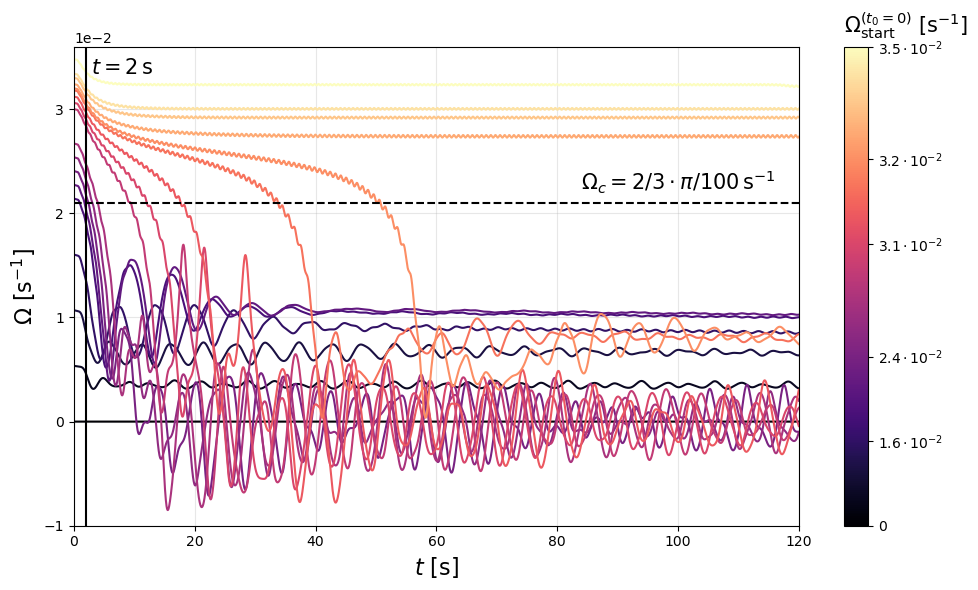

In [ ]:
fig,ax=plt.subplots(figsize=(10,6))

guess=2 * np.pi / 100 * 1/3

for i in range(len(runs_sorted)):
    obj = runs_sorted[i]
    color = cmap(norm(i))
    ax.plot((obj.t),(obj.Omega),label=f'{obj.o:.4f}', color=color)

ax.set_ylabel(r'$\Omega$ [$\mathrm{s}^{-1}$]', size=16)
ax.set_xlabel(r'$t$ [$\mathrm{s}$]', size=16)
ax.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
ax.set_xlim(0,120)
ax.set_ylim(-0.01,0.036)

ax.axhline(guess, color='black', label=r'$\frac{2\pi}{300}$', ls='--')
ax.vlines(2, -0.01, 0.036, color='black', ls='-', label=r'$t=2\mathrm{s}$')

plt.text(8, 0.034, r'$t=2 \,\mathrm{s}$', ha='center', va='center', size=15)
plt.text(100, 0.023, r'$\Omega_{c} =2/3 \cdot \pi/100 \, \mathrm{s}^{-1}$', ha='center', va='center', size=15)

cbar1 = fig.colorbar(sm, ax=ax)
cbar1.ax.set_title(r'$\Omega_{\mathrm{start}}^{(t_0=0)}$ [$\mathrm{s}^{-1}$]', size=15, pad=10, loc='left')
cbar1.set_ticks(tick_locs)
cbar1.set_ticklabels(tick_labels)

plt.grid(alpha=0.3)
plt.tight_layout()
#plt.savefig('abra1_grid.png', dpi=300, format='png', bbox_inches='tight')

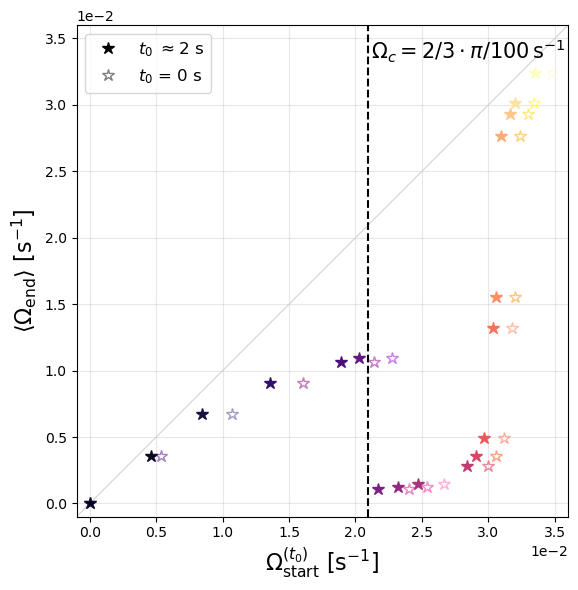

In [ ]:
fig,ax=plt.subplots(figsize=(6,6))

x=np.linspace(-0.001, 0.036, 100)
ax.plot(x, x, color='lightgrey', linestyle='-', linewidth=0.8)

ax.axvline(guess, color='black', ls='--')

for i in range(len(runs_sorted)):
    run = runs_sorted[i]
    color = cmap(norm(i))
    ax.plot((run.Omega[run.t>=2])[0], np.mean(run.Omega[:-50]), '*', color=color, markersize=9)
    ax.plot(run.Omega[0], np.mean(run.Omega[:-50]), '*', color=colors_plasma[i], markersize=9, fillstyle='none', alpha=0.5)

ax.plot(-5, -5, color='black', marker='*', ls='', markersize=9,label=r'$t_0$ $\approx 2$ s')
ax.plot(-5, -5, color='black', marker='*', ls='', markersize=9,label=r'$t_0$ = 0 s', fillstyle='none', alpha=0.5)
ax.set_xlabel(r'$\Omega_{\mathrm{start}}^{(t_0)}$ [$\mathrm{s}^{-1}$]', size=16)
ax.set_ylabel(r'$\langle \Omega _{\mathrm{end}}\rangle$ [$\mathrm{s}^{-1}$]', size=16)

ax.set_aspect('equal', adjustable='box')
ax.ticklabel_format(axis='y', style='sci', scilimits=(0,0))
ax.ticklabel_format(axis='x', style='sci', scilimits=(0,0))

plt.text(0.0285, 0.034, r'$\Omega_{c} =2/3 \cdot \pi/100 \, \mathrm{s}^{-1}$', ha='center', va='center', size=15)

ax.set_xlim(-0.001, 0.036)
ax.set_ylim(-0.001,0.036)
ax.legend(loc='upper left', fontsize=12)
plt.grid(alpha=0.3)
plt.tight_layout()

#plt.savefig('abra2_grid.png', dpi=300, format='png', bbox_inches='tight')

## Fonon spektrum

In [7]:
k_vals = np.linspace(-np.pi, np.pi, 500)
Omega_vals = 2*np.abs(np.sin(k_vals/2))

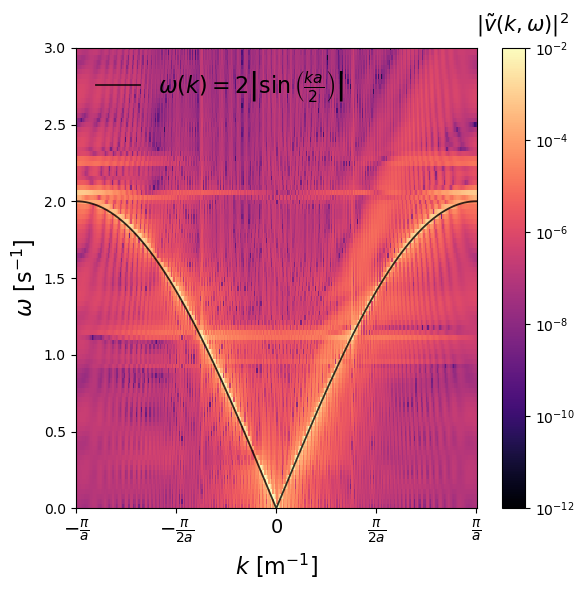

In [26]:
fig, ax = plt.subplots(figsize=(6,6))

norm = colors.LogNorm(vmin=1e-10, vmax=1e-2)

phonon_data.phonon_spectrum(ax=ax, cmap='magma')

artist = ax.collections[-1] if ax.collections else ax.images[-1]
artist.set_norm(colors.LogNorm(vmin=1e-12, vmax=1e-2))

cbar = artist.colorbar

cbar.update_normal(artist) 
cbar.ax.set_title(r'$|\tilde{v}(k, \omega)|^2$', size=15, pad=12, x=0.9, ha='center')
ax.plot(k_vals, Omega_vals, color='black', label=r'$\omega (k) = 2\left|\sin\left(\frac{ka}{2}\right)\right|$', ls='-', linewidth=1.3, alpha=0.8)

ax.legend(loc='upper left', fontsize=16, framealpha=0)

ax.set_xlabel(r'$k ~ \mathrm{[m^{-1}]}$', size=16)
ax.set_ylabel(r'$\omega ~ \mathrm{[s^{-1}]}$', size=16)

ax.set_xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi],labels=[r'$-\frac{\pi}{a}$', r'$-\frac{\pi}{2a}$', r'$0$', r'$\frac{\pi}{2a}$', r'$\frac{\pi}{a}$'],fontsize=14)

plt.tight_layout()
#plt.savefig('fonon.png', dpi=300, format='png', bbox_inches='tight')